# Hand2Panda — Phase 2: retargeting the human motion prior into LIBERO / Panda

Continues from `01_video_to_motion_prior.ipynb`. Loads the motion prior fitted on the phone videos, builds the
`libero_spatial` task 0 scene, calibrates a Cartesian controller for the Panda arm, and runs pick-and-place
with different carry-path shapes (straight line, human median, individual human demos incl. held-out L5/L6).

Only the normalised 2D path shape comes from the phone data. Approach, grasp, lift, lower and release are
geometric because the height estimates from the videos were not reliable. Run top to bottom in Colab.

Results of the full evaluation are in `results/` and summarised in the README.


## 0. Dependencies

If this notebook is running in a fresh Colab runtime, the LeRobot/LIBERO dependencies from the original smoke-test notebook may not be installed. Run the next cell; it skips installation if the core packages are already importable. A first-time installation can take several minutes.

In [2]:
%%bash
set -e
if python - <<'PY'
from importlib.util import find_spec
required = ["torch", "cv2", "mujoco", "robosuite", "libero", "lerobot"]
missing = [name for name in required if find_spec(name) is None]
print("Missing modules:", missing)
raise SystemExit(1 if missing else 0)
PY
then
  echo "Core dependencies already available; skipping installation."
else
  echo "Installing the pinned LeRobot/LIBERO stack..."
  apt-get -qq update
  apt-get -qq install -y libegl1 libgl1 libglfw3 libosmesa6 ffmpeg > /dev/null
  pip install -q cmake
  cd /content
  if [ ! -d lerobot_repo ]; then
    git clone --depth 1 --branch v0.6.1 https://github.com/huggingface/lerobot.git lerobot_repo
  fi
  cd /content/lerobot_repo
  pip install -q -e ".[smolvla,libero]"
fi

Missing modules: ['mujoco', 'robosuite', 'libero', 'lerobot']
Installing the pinned LeRobot/LIBERO stack...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.7/217.7 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.9/192.9 kB 9.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.8/164.8 kB 12.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.5/42.5 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.5/217.5 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.5/193.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Cloning into 'lerobot_repo'...
Note: switching to '7e241bd630a3719a56157a497ce5d08f244784f1'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false



## 1. Configure imports and LIBERO's non-interactive paths

In [3]:
import os
import sys
import importlib.util
import importlib.metadata as metadata
from pathlib import Path

# Match the working smoke-test environment.
sys.path.insert(0, "/content/lerobot_repo/src")
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["LIBERO_CONFIG_PATH"] = "/content/.libero"

cfg_dir = Path(os.environ["LIBERO_CONFIG_PATH"])
cfg_dir.mkdir(parents=True, exist_ok=True)
cfg_file = cfg_dir / "config.yaml"

if not cfg_file.exists():
    spec = importlib.util.find_spec("libero")
    if spec is None or not spec.submodule_search_locations:
        raise ModuleNotFoundError(
            "LIBERO could not be imported. Run the dependency cell and, if Colab asks, restart the runtime."
        )
    benchmark_root = None
    for root in spec.submodule_search_locations:
        root = Path(root)
        for candidate in (root / "libero", root):
            if (candidate / "bddl_files").exists() and (candidate / "init_files").exists():
                benchmark_root = candidate
                break
        if benchmark_root is not None:
            break
    if benchmark_root is None:
        print("WARNING: could not locate LIBERO's asset directories; relying on package defaults.")
    else:
        cfg_file.write_text(
            f"benchmark_root: {benchmark_root}\n"
            f"bddl_files: {benchmark_root}/bddl_files\n"
            f"init_states: {benchmark_root}/init_files\n"
            f"datasets: {benchmark_root.parent}/datasets\n"
            f"assets: {benchmark_root}/assets\n"
        )
        print("Wrote LIBERO config:", cfg_file)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from google.colab import drive
from libero.libero import benchmark, get_libero_path
from libero.libero.envs import OffScreenRenderEnv

drive.mount('/content/drive', force_remount=False)

for package in ["torch", "lerobot", "mujoco", "robosuite", "hf-libero"]:
    try:
        print(f"{package:12s}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package:12s}: version not available")
print("CUDA available:", torch.cuda.is_available())
print("LIBERO/Lerobot imports OK")

Wrote LIBERO config: /content/.libero/config.yaml


[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /usr/local/lib/python3.13/dist-packages/robosuite/scripts/setup_macros.py (__init__.py:9)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Mounted at /content/drive
torch       : 2.11.0+cpu
lerobot     : 0.6.1
mujoco      : 3.8.1
robosuite   : 1.4.0
hf-libero   : 0.1.4
CUDA available: False
LIBERO/Lerobot imports OK


## 2. Load the saved motion prior and keep the held-out data separate

The clean pipeline writes `motion_prior.npz` and `normalized_xy_paths.npz` to the Drive output folder below. If your folder was moved, update `DATA_DIR`.

Motion prior: /content/drive/MyDrive/Humanoid/clean_pipeline_outputs/normalized_dataset/motion_prior.npz
Training demonstrations: [np.str_('L1_01'), np.str_('L1_02'), np.str_('L1_03'), np.str_('L1_04'), np.str_('L2_01'), np.str_('L2_02'), np.str_('L2_03'), np.str_('L2_04'), np.str_('L3_01'), np.str_('L3_02'), np.str_('L3_03'), np.str_('L3_04'), np.str_('L4_01'), np.str_('L4_02'), np.str_('L4_03'), np.str_('L4_04')]
Held-out demonstrations (not used for fitting): [np.str_('L5_01'), np.str_('L5_02'), np.str_('L6_01'), np.str_('L6_02')]
Median path start: [0. 0.]
Median path middle: [0.5837 0.0334]
Median path end: [ 1. -0.]


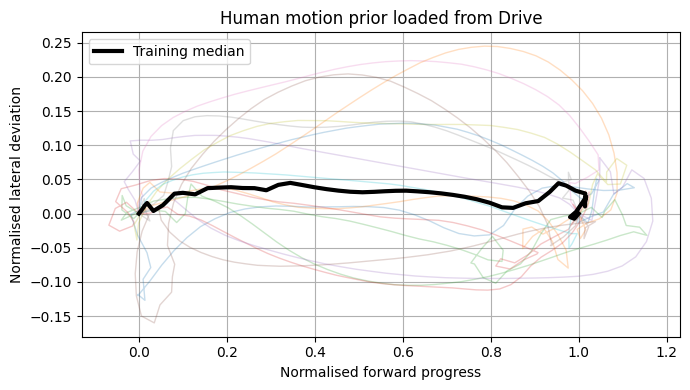

In [4]:
DATA_DIR = Path('/content/drive/MyDrive/Humanoid/clean_pipeline_outputs/normalized_dataset')
PRIOR_FILE = DATA_DIR / 'motion_prior.npz'
PATHS_FILE = DATA_DIR / 'normalized_xy_paths.npz'

assert PRIOR_FILE.exists(), f'Motion prior not found: {PRIOR_FILE}'
assert PATHS_FILE.exists(), f'Normalised paths not found: {PATHS_FILE}'

prior = np.load(PRIOR_FILE)
paths_data = np.load(PATHS_FILE)
median_path = np.asarray(prior['median_path'], dtype=np.float64)
train_paths = np.asarray(paths_data['train_paths'], dtype=np.float64)
train_names = paths_data['train_names'].astype(str)
test_paths = np.asarray(paths_data['test_paths'], dtype=np.float64)
test_names = paths_data['test_names'].astype(str)

assert median_path.shape == (50, 2), f'Unexpected median path shape: {median_path.shape}'
assert train_paths.shape == (16, 50, 2), f'Unexpected training shape: {train_paths.shape}'
assert test_paths.shape == (4, 50, 2), f'Unexpected held-out shape: {test_paths.shape}'
assert np.isfinite(median_path).all() and np.isfinite(train_paths).all() and np.isfinite(test_paths).all()

print('Motion prior:', PRIOR_FILE)
print('Training demonstrations:', list(train_names))
print('Held-out demonstrations (not used for fitting):', list(test_names))
print('Median path start:', np.round(median_path[0], 4))
print('Median path middle:', np.round(median_path[len(median_path)//2], 4))
print('Median path end:', np.round(median_path[-1], 4))

plt.figure(figsize=(7, 4))
for name, path in zip(train_names, train_paths):
    plt.plot(path[:, 0], path[:, 1], alpha=0.25, linewidth=1)
plt.plot(median_path[:, 0], median_path[:, 1], color='black', linewidth=3, label='Training median')
plt.xlabel('Normalised forward progress')
plt.ylabel('Normalised lateral deviation')
plt.title('Human motion prior loaded from Drive')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Create the fixed LIBERO task scene

This reuses the exact benchmark, task, and initial-state workflow that worked in the smoke-test notebook. This cell does not load SmolVLA and does not run a policy.

In [5]:
SUITE_NAME = 'libero_spatial'
TASK_ID = 0
CAMERA_HEIGHT = 256
CAMERA_WIDTH = 256
NOOP_OPEN = np.array([0, 0, 0, 0, 0, 0, -1.0], dtype=np.float32)

suite = benchmark.get_benchmark_dict()[SUITE_NAME]()
task = suite.get_task(TASK_ID)
print('Task instruction:', task.language)

bddl_path = os.path.join(
    get_libero_path('bddl_files'), task.problem_folder, task.bddl_file
)
init_path = os.path.join(
    get_libero_path('init_states'), task.problem_folder, task.init_states_file
)

try:
    env.close()
except Exception:
    pass

env = OffScreenRenderEnv(
    bddl_file_name=bddl_path,
    camera_heights=CAMERA_HEIGHT,
    camera_widths=CAMERA_WIDTH,
)
init_states = torch.load(init_path, weights_only=False)

def reset_to_fixed_state(settle_steps=10):
    """Restore the first official LIBERO initial state and let it settle."""
    env.seed(0)
    env.reset()
    current_obs = env.set_init_state(init_states[0])
    for _ in range(settle_steps):
        current_obs, *_ = env.step(NOOP_OPEN)
    return current_obs

obs = reset_to_fixed_state()
print('Initial EEF position (world m):', np.round(obs['robot0_eef_pos'], 4))
print('Observation keys:', [k for k in obs if 'image' in k or 'eef' in k or 'gripper' in k])

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Task instruction: pick up the black bowl between the plate and the ramekin and place it on the plate
Local assets not found. Downloading from HuggingFace Hub...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `snapshot_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 586 files:   0%|          | 0/586 [00:00<?, ?it/s]

Assets downloaded successfully to /root/.cache/libero/assets


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Initial EEF position (world m): [-0.2112 -0.0111  1.1742]
Observation keys: ['robot0_eef_pos', 'robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_gripper_qvel', 'agentview_image', 'robot0_eye_in_hand_image', 'akita_black_bowl_1_to_robot0_eef_pos', 'akita_black_bowl_1_to_robot0_eef_quat', 'akita_black_bowl_2_to_robot0_eef_pos', 'akita_black_bowl_2_to_robot0_eef_quat', 'cookies_1_to_robot0_eef_pos', 'cookies_1_to_robot0_eef_quat', 'glazed_rim_porcelain_ramekin_1_to_robot0_eef_pos', 'glazed_rim_porcelain_ramekin_1_to_robot0_eef_quat', 'plate_1_to_robot0_eef_pos', 'plate_1_to_robot0_eef_quat']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4. View the scene before selecting the target object

The instruction refers to the black bowl between the plate and ramekin. There are two black bowls in this task, so do not choose a bowl by suffix alone. Use the image plus the world-coordinate listing in the next cell.

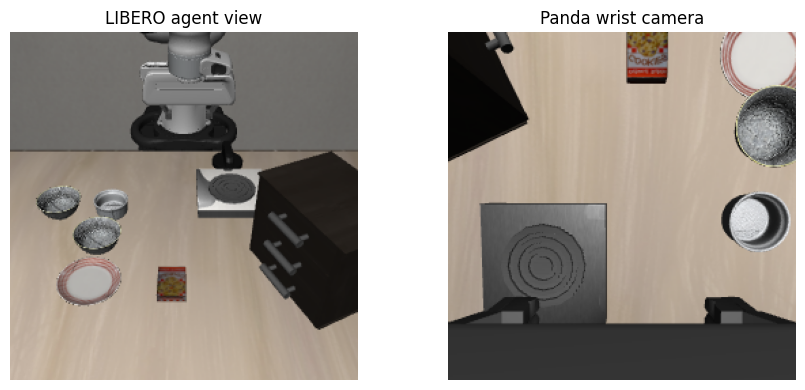

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(obs['agentview_image'][::-1, ::-1])
ax[0].set_title('LIBERO agent view')
ax[1].imshow(obs['robot0_eye_in_hand_image'][::-1, ::-1])
ax[1].set_title('Panda wrist camera')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

In [7]:
# Enumerate MuJoCo body names and world positions.
model = env.sim.model
sim_data = env.sim.data

if hasattr(model, 'body_names'):
    RAW_BODY_NAMES = list(model.body_names)
elif hasattr(model, 'nbody') and hasattr(model, 'body_id2name'):
    RAW_BODY_NAMES = [model.body_id2name(i) for i in range(model.nbody)]
else:
    raise RuntimeError('Could not enumerate MuJoCo body names using this LIBERO build.')

BODY_NAMES = [name.decode('utf-8') if isinstance(name, bytes) else str(name) for name in RAW_BODY_NAMES]

def body_position(body_name):
    """Return a copy of a named MuJoCo body's world XYZ position in metres."""
    if body_name not in BODY_NAMES:
        raise KeyError(f'Body {body_name!r} not found. Inspect BODY_NAMES and use an exact name.')
    body_id = BODY_NAMES.index(body_name)
    return np.asarray(sim_data.body_xpos[body_id], dtype=float).copy()

KEYWORDS = ('akita_black_bowl', 'plate', 'ramekin')
RELEVANT_BODIES = []
print('Relevant object bodies (world coordinates, metres):')
for idx, name in enumerate(BODY_NAMES):
    if any(word in name.lower() for word in KEYWORDS):
        pos = np.asarray(sim_data.body_xpos[idx], dtype=float)
        RELEVANT_BODIES.append((name, pos.copy()))
        print(f'{name:48s} {np.round(pos, 4)}')

print('\nObject-to-EEF observation keys (relative positions, as reported by LIBERO):')
for key in obs:
    if key.endswith('_to_robot0_eef_pos'):
        print(f'{key:52s} {np.round(obs[key], 4)}')

# Diagnostic only: which bowl lies closest to the segment joining plate and ramekin?
bowl_names = [name for name in BODY_NAMES if name.startswith('akita_black_bowl_')]
plate_names = [name for name in BODY_NAMES if name == 'plate_1']
ramekin_names = [name for name in BODY_NAMES if name.startswith('glazed_rim_porcelain_ramekin_')]
if bowl_names and plate_names and ramekin_names:
    p = body_position(plate_names[0])[:2]
    r = body_position(ramekin_names[0])[:2]
    v = r - p
    denom = max(float(np.dot(v, v)), 1e-12)
    print('\nBowl position relative to plate–ramekin segment (diagnostic only):')
    for name in bowl_names:
        b = body_position(name)[:2]
        u = float(np.dot(b - p, v) / denom)
        closest = p + np.clip(u, 0, 1) * v
        perpendicular_cm = float(np.linalg.norm(b - closest) * 100)
        print(f'{name}: segment_parameter={u:.3f}, perpendicular_distance={perpendicular_cm:.2f} cm')
else:
    print('\nCould not calculate bowl-between-plate-and-ramekin diagnostic: expected body names not found.')

Relevant object bodies (world coordinates, metres):
akita_black_bowl_1_main                          [-0.0635  0.202   0.8984]
akita_black_bowl_2_main                          [-0.1887  0.3203  0.8984]
glazed_rim_porcelain_ramekin_1_main              [-0.1974  0.1891  0.8993]
plate_1_main                                     [0.0534 0.2052 0.9025]
flat_stove_1_burner_plate                        [-0.2671 -0.1311  0.905 ]

Object-to-EEF observation keys (relative positions, as reported by LIBERO):
akita_black_bowl_1_to_robot0_eef_pos                 [ 0.1626 -0.2133  0.2673]
akita_black_bowl_2_to_robot0_eef_pos                 [ 0.0373 -0.3313  0.2743]
cookies_1_to_robot0_eef_pos                          [ 0.2834 -0.0379  0.2495]
glazed_rim_porcelain_ramekin_1_to_robot0_eef_pos     [ 0.0288 -0.2001  0.2738]
plate_1_to_robot0_eef_pos                            [ 0.279  -0.2166  0.2567]

Could not calculate bowl-between-plate-and-ramekin diagnostic: expected body names not found.


## 5. Calibrate the raw end-effector action directions safely

The raw LIBERO action is seven-dimensional: three translation commands, three rotation commands, and a gripper command (`-1` open; `+1` close, as used in the smoke test). This cell probes each translation axis with one small command, measures the observed EEF displacement, then restores the original initial state.

In [8]:
PROBE_ACTION_MAGNITUDE = 0.10
PROBE_STEPS = 6

EEF_ACTION_JACOBIAN = np.zeros((3, 3), dtype=float)
probe_records = []

for axis in range(3):
    obs = reset_to_fixed_state()

    before = np.asarray(
        obs["robot0_eef_pos"], dtype=float
    ).copy()

    action = np.zeros(7, dtype=np.float32)
    action[axis] = PROBE_ACTION_MAGNITUDE
    action[6] = -1.0  # Keep gripper open.

    for _ in range(PROBE_STEPS):
        obs, *_ = env.step(action)

    after = np.asarray(
        obs["robot0_eef_pos"], dtype=float
    ).copy()

    delta = after - before

    EEF_ACTION_JACOBIAN[:, axis] = (
        delta / (PROBE_ACTION_MAGNITUDE * PROBE_STEPS)
    )

    probe_records.append({
        "axis": ["x", "y", "z"][axis],
        "delta_x_m": delta[0],
        "delta_y_m": delta[1],
        "delta_z_m": delta[2],
    })

obs = reset_to_fixed_state()

display(pd.DataFrame(probe_records).round(5))

print("Translation Jacobian:")
print(np.round(EEF_ACTION_JACOBIAN, 5))
print("Rank:", np.linalg.matrix_rank(EEF_ACTION_JACOBIAN))

,axis,delta_x_m,delta_y_m,delta_z_m
0,x,0.00525,0.00004,-0.00123
1,y,0.00003,0.00645,-0.00003
2,z,-0.00046,0.00005,0.00651


Translation Jacobian:
[[ 8.750e-03  4.000e-05 -7.600e-04]
 [ 7.000e-05  1.075e-02  9.000e-05]
 [-2.050e-03 -5.000e-05  1.084e-02]]
Rank: 3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6. Confirm the object names (required before any pick-and-place)

Read the exact body names printed above. Confirm in the rendered image which bowl is the black bowl described by the task instruction. Then edit `TARGET_BOWL_BODY` below to that exact name and leave `PLATE_BODY` as `plate_1` if that exact body appeared in the listing. **Do not run the manipulation cell until these are confirmed.**

In [9]:
TARGET_BOWL_BODY = "akita_black_bowl_1_main"
PLATE_BODY = "plate_1_main"

print("Target bowl:", TARGET_BOWL_BODY)
print("Plate:", PLATE_BODY)

assert TARGET_BOWL_BODY in BODY_NAMES
assert PLATE_BODY in BODY_NAMES

print("Bowl position (m):", np.round(
    body_position(TARGET_BOWL_BODY), 4
))
print("Plate position (m):", np.round(
    body_position(PLATE_BODY), 4
))

Target bowl: akita_black_bowl_1_main
Plate: plate_1_main
Bowl position (m): [-0.0635  0.202   0.8984]
Plate position (m): [0.0534 0.2052 0.9025]


## 7. Preview the retargeted human path

This only computes and plots waypoints; it does not move the robot. It maps normalised `along/lateral` values into the simulator's observed bowl-to-plate XY direction and distance. It deliberately uses a generated fixed carry height later, not the unreliable recorded Z estimates.

Simulated bowl start XYZ (m): [-0.0635  0.202   0.8984]
Simulated plate-body XYZ (m): [0.0534 0.2052 0.9025]
XY start-to-goal distance (cm): 11.69


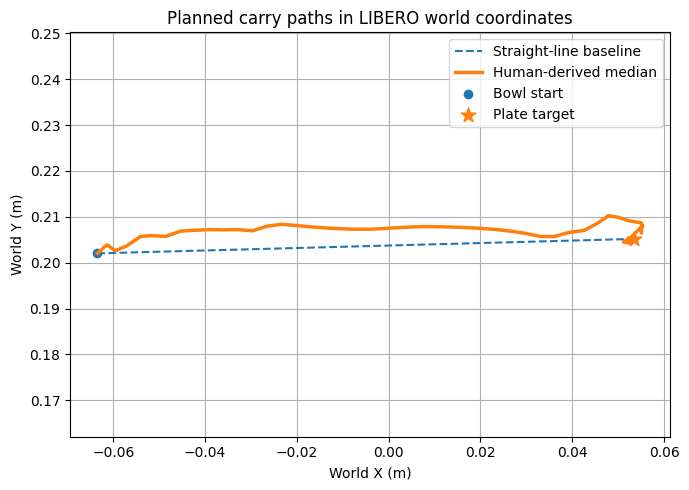

In [10]:
def map_canonical_path_to_world_xy(canonical_path, start_xyz, goal_xyz):
    """Map [normalised along, normalised lateral] path into world XY coordinates."""
    start_xy = np.asarray(start_xyz[:2], dtype=float)
    goal_xy = np.asarray(goal_xyz[:2], dtype=float)
    displacement = goal_xy - start_xy
    distance = np.linalg.norm(displacement)
    if distance < 1e-4:
        raise ValueError('Start and goal XY positions are too close to retarget.')
    forward = displacement / distance
    lateral = np.array([-forward[1], forward[0]])
    path = np.asarray(canonical_path, dtype=float)
    return start_xy[None, :] + (path[:, 0:1] * distance) * forward[None, :] + (path[:, 1:2] * distance) * lateral[None, :]

if TARGET_BOWL_BODY is None or PLATE_BODY is None:
    print('Set TARGET_BOWL_BODY and PLATE_BODY in Cell 8 first; preview skipped.')
else:
    start_xyz = body_position(TARGET_BOWL_BODY)
    goal_xyz = body_position(PLATE_BODY)
    human_xy = map_canonical_path_to_world_xy(median_path, start_xyz, goal_xyz)
    line_t = np.linspace(0, 1, len(median_path))
    straight_xy = start_xyz[:2][None, :] + line_t[:, None] * (goal_xyz[:2] - start_xyz[:2])[None, :]
    print('Simulated bowl start XYZ (m):', np.round(start_xyz, 4))
    print('Simulated plate-body XYZ (m):', np.round(goal_xyz, 4))
    print('XY start-to-goal distance (cm):', round(np.linalg.norm(goal_xyz[:2] - start_xyz[:2]) * 100, 2))
    plt.figure(figsize=(7, 5))
    plt.plot(straight_xy[:, 0], straight_xy[:, 1], '--', label='Straight-line baseline')
    plt.plot(human_xy[:, 0], human_xy[:, 1], linewidth=2.5, label='Human-derived median')
    plt.scatter([start_xyz[0]], [start_xyz[1]], marker='o', label='Bowl start')
    plt.scatter([goal_xyz[0]], [goal_xyz[1]], marker='*', s=120, label='Plate target')
    plt.xlabel('World X (m)')
    plt.ylabel('World Y (m)')
    plt.title('Planned carry paths in LIBERO world coordinates')
    plt.axis('equal')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 8. Closed-loop Cartesian control utilities

These functions use the measured small-action Jacobian and re-check the end-effector position after every step. They are an initial experimental controller, not a validated production controller. Tune only in simulation and inspect the resulting video. The controller is not called automatically in this cell.

In [11]:
MAX_TRANSLATION_ACTION = 0.35
EEF_POSITION_TOLERANCE_M = 0.005
MAX_STEPS_PER_TARGET = 300

# Grasp offsets copied from the successful manual grasp test.
GRASP_EEF_X_OFFSET_M = 0.00
GRASP_EEF_Y_OFFSET_M = 0.02
GRASP_EEF_Z_OFFSET_M = 0.02

# Manual test: 11 cm above the selected grasp target.
# Since the grasp Z offset is 2 cm, pregrasp is 13 cm
# above the bowl's starting Z position.
PREGRASP_HEIGHT_M = 0.13

CARRY_CLEARANCE_M = 0.12
PLACE_EEF_Z_OFFSET_M = 0.07
CARRY_WAYPOINTS = 12
GRIPPER_CLOSE_STEPS = 20

print("Grasp X offset:", GRASP_EEF_X_OFFSET_M, "m")
print("Grasp Y offset:", GRASP_EEF_Y_OFFSET_M, "m")
print("Grasp Z offset:", GRASP_EEF_Z_OFFSET_M, "m")
# GIF recorder — fixed version
_CAPTURE_FRAMES = []
_CAPTURE_STEP_COUNT = 0

def _capture_current_frame():
    global _CAPTURE_STEP_COUNT

    _CAPTURE_STEP_COUNT += 1

    if "agentview_image" not in obs:
        return

    # Capture every third simulation step.
    if _CAPTURE_STEP_COUNT % 3 == 0:
        frame = np.asarray(obs["agentview_image"])

        # Keep the orientation consistent with your scene display.
        frame = frame[::-1, ::-1].copy()

        _CAPTURE_FRAMES.append(frame)

print("Recorder initialised.")
print("Capture frequency: every 3 simulation steps.")

def move_eef_to(target_xyz, gripper=-1.0, max_steps=MAX_STEPS_PER_TARGET, verbose=False):
    """Closed-loop EEF position move using calibrated translation-action Jacobian."""
    global obs
    target_xyz = np.asarray(target_xyz, dtype=float).reshape(3)
    if np.linalg.matrix_rank(EEF_ACTION_JACOBIAN) < 3:
        raise RuntimeError('EEF action Jacobian is not full rank; do not actuate.')
    jac_inv = np.linalg.pinv(EEF_ACTION_JACOBIAN)
    for step_idx in range(max_steps):
        current = np.asarray(obs['robot0_eef_pos'], dtype=float)
        error = target_xyz - current
        if np.linalg.norm(error) <= EEF_POSITION_TOLERANCE_M:
            if verbose:
                print(f'Reached target within tolerance in {step_idx} steps; error={np.linalg.norm(error):.4f} m')
            return True
        xyz_action = np.clip(jac_inv @ error, -MAX_TRANSLATION_ACTION, MAX_TRANSLATION_ACTION)
        action = np.zeros(7, dtype=np.float32)
        action[:3] = xyz_action
        action[6] = float(gripper)
        obs, *_ = env.step(action)
        _capture_current_frame()
    final_error = float(np.linalg.norm(target_xyz - np.asarray(obs['robot0_eef_pos'], dtype=float)))
    print(f'WARNING: move target not reached in {max_steps} steps; final error={final_error:.4f} m')
    return final_error <= EEF_POSITION_TOLERANCE_M

def command_gripper(command, steps=10):
    """Hold position while commanding the gripper: -1=open, +1=close."""
    global obs
    if command not in (-1, 1, -1.0, 1.0):
        raise ValueError('Gripper command must be -1 (open) or +1 (close).')
    action = np.zeros(7, dtype=np.float32)
    action[6] = float(command)
    for _ in range(steps):
        obs, *_ = env.step(action)
        _capture_current_frame()

def get_task_success_if_available():
    """Use an environment success checker if exposed; otherwise return None."""
    for owner in (env, getattr(env, 'env', None)):
        if owner is None:
            continue
        for method_name in ('check_success', '_check_success'):
            method = getattr(owner, method_name, None)
            if callable(method):
                try:
                    return bool(method())
                except Exception:
                    pass
    return None

print('Controller functions defined; nothing has moved.')
print('Translation Jacobian rank:', np.linalg.matrix_rank(EEF_ACTION_JACOBIAN))
print('Current EEF position:', np.round(obs['robot0_eef_pos'], 4))

Grasp X offset: 0.0 m
Grasp Y offset: 0.02 m
Grasp Z offset: 0.02 m
Recorder initialised.
Capture frequency: every 3 simulation steps.
Controller functions defined; nothing has moved.
Translation Jacobian rank: 3
Current EEF position: [-0.2112 -0.0111  1.1742]


## Manual grasp-and-lift check
Before building the full runner, one grasp + 2 cm lift was run by hand to confirm that the bowl follows the gripper and to measure the grasp offsets used below.

In [14]:

import numpy as np
import matplotlib.pyplot as plt
import imageio.v2 as imageio

from pathlib import Path
from IPython.display import display, Image

# ============================================================
# EDIT THESE VALUES FOR EACH TEST (metres)
# ============================================================

DX = -0.00
DY =  0.02
DZ =  0.02

APPROACH_CLEARANCE = 0.11

CLOSE_GRIPPER_AT_TARGET = True
TEST_LIFT = True
LIFT_DISTANCE = 0.02

# Record every 2 simulation steps.
RECORD_EVERY_N_STEPS = 2

# ============================================================
# OUTPUT FILE
# ============================================================

if Path("/content/drive/MyDrive").exists():
    OUTPUT_DIR = Path(
        "/content/drive/MyDrive/Humanoid/clean_pipeline_outputs"
    )
else:
    OUTPUT_DIR = Path("/content")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GIF_PATH = OUTPUT_DIR / "manual_grasp_test_full_environment.gif"

# ============================================================
# LIVE POSITION AND OBSERVATION HELPERS
# ============================================================

def live_body_position(body_name):
    """Read the body's current world position directly from MuJoCo."""
    model = env.sim.model
    data = env.sim.data

    if hasattr(model, "body_name2id"):
        body_id = model.body_name2id(body_name)
    else:
        names = [
            n.decode("utf-8") if isinstance(n, bytes) else n
            for n in model.body_names
        ]
        body_id = names.index(body_name)

    return np.asarray(data.body_xpos[body_id], dtype=float).copy()


def latest_observation(fallback_obs):
    """Return the newest observation captured from env.step()."""
    current = record_state.get("latest_obs")

    if isinstance(current, dict):
        return current

    return fallback_obs


# ============================================================
# VALIDATION AND ACTIONS
# ============================================================

assert not TEST_LIFT or CLOSE_GRIPPER_AT_TARGET, (
    "TEST_LIFT requires CLOSE_GRIPPER_AT_TARGET=True"
)

OPEN = np.array(
    [0, 0, 0, 0, 0, 0, -1.0], dtype=np.float32
)
CLOSE = np.array(
    [0, 0, 0, 0, 0, 0, 1.0], dtype=np.float32
)

CAPTURED_FRAMES = []
record_state = {"steps": 0, "latest_obs": None}


def capture_observation(observation):
    """Capture the full external camera image."""
    if not isinstance(observation, dict):
        return

    if "agentview_image" not in observation:
        return

    frame = np.asarray(observation["agentview_image"])
    frame = frame[::-1, ::-1].copy()

    CAPTURED_FRAMES.append(
        np.ascontiguousarray(frame, dtype=np.uint8)
    )


# ============================================================
# RESET SCENE AND START RECORDING
# ============================================================

obs = reset_to_fixed_state()

bowl_start = live_body_position(TARGET_BOWL_BODY)

grasp_target = bowl_start + np.array([DX, DY, DZ])

pregrasp_target = grasp_target + np.array([
    0.0, 0.0, APPROACH_CLEARANCE
])

print("=" * 60)
print("FULL-ENVIRONMENT GRASP AND LIFT TEST")
print("=" * 60)
print("Bowl starting position:", np.round(bowl_start, 4))
print("Pregrasp target:", np.round(pregrasp_target, 4))
print("Grasp target:", np.round(grasp_target, 4))
print(
    f"Offsets: DX={DX*100:.1f} cm, "
    f"DY={DY*100:.1f} cm, DZ={DZ*100:.1f} cm"
)
print(f"Requested lift: {LIFT_DISTANCE*100:.1f} cm")

capture_observation(obs)

# Intercept every environment step, including steps executed
# internally by move_eef_to().
original_step = env.step


def recording_step(*args, **kwargs):
    result = original_step(*args, **kwargs)

    record_state["steps"] += 1

    if isinstance(result, (tuple, list)) and len(result) > 0:
        new_obs = result[0]

        if isinstance(new_obs, dict):
            record_state["latest_obs"] = new_obs

            if (
                record_state["steps"] % RECORD_EVERY_N_STEPS == 0
            ):
                capture_observation(new_obs)

    return result


# ============================================================
# RUN THE TEST WHILE CAPTURING EVERY STAGE
# ============================================================

env.step = recording_step

try:
    # 1. Approach from above with the gripper open.
    approach_ok = move_eef_to(
        pregrasp_target,
        gripper=-1.0,
        max_steps=300,
        verbose=True,
    )

    # 2. Descend to the candidate grasp position.
    position_ok = False

    if approach_ok:
        position_ok = move_eef_to(
            grasp_target,
            gripper=-1.0,
            max_steps=300,
            verbose=True,
        )

    obs = latest_observation(obs)

    print("\nApproach reached:", approach_ok)
    print("Grasp position reached:", position_ok)
    print(
        "Actual EEF position:",
        np.round(obs["robot0_eef_pos"], 4)
    )

    capture_observation(obs)

    # Measure the bowl immediately BEFORE closing.
    bowl_before_close = live_body_position(TARGET_BOWL_BODY)

    # 3. Close the gripper.
    if position_ok and CLOSE_GRIPPER_AT_TARGET:
        for _ in range(20):
            obs, *_ = env.step(CLOSE)

        obs = latest_observation(obs)
        bowl_after_close = live_body_position(TARGET_BOWL_BODY)

        print("\n--- GRIPPER CLOSURE ---")
        print(
            "Bowl before closing:",
            np.round(bowl_before_close, 4)
        )
        print(
            "Bowl after closing:",
            np.round(bowl_after_close, 4)
        )
        print(
            "Vertical movement during closing (cm):",
            round(
                (bowl_after_close[2] - bowl_before_close[2]) * 100,
                2,
            ),
        )

        capture_observation(obs)

        # 4. Command a lift and measure movement specifically
        #    during that command.
        if TEST_LIFT:
            obs = latest_observation(obs)

            eef_before_lift = np.asarray(
                obs["robot0_eef_pos"], dtype=float
            ).copy()

            bowl_before_lift = live_body_position(
                TARGET_BOWL_BODY
            )

            lift_target = eef_before_lift + np.array([
                0.0, 0.0, LIFT_DISTANCE
            ])

            print("\n--- COMMANDED LIFT ---")
            print(
                "EEF before lift:",
                np.round(eef_before_lift, 4)
            )
            print(
                "Bowl before lift:",
                np.round(bowl_before_lift, 4)
            )
            print(
                "Lift target:",
                np.round(lift_target, 4)
            )

            lift_ok = move_eef_to(
                lift_target,
                gripper=1.0,
                max_steps=300,
                verbose=True,
            )

            # Keep gripper closed while the scene settles.
            for _ in range(5):
                obs, *_ = env.step(CLOSE)

            obs = latest_observation(obs)

            eef_after_lift = np.asarray(
                obs["robot0_eef_pos"], dtype=float
            ).copy()

            bowl_after_lift = live_body_position(
                TARGET_BOWL_BODY
            )

            # Movement DURING the lift command.
            eef_dz_cm = (
                eef_after_lift[2] - eef_before_lift[2]
            ) * 100

            bowl_dz_cm = (
                bowl_after_lift[2] - bowl_before_lift[2]
            ) * 100

            # Total movement since the reset.
            total_bowl_rise_cm = (
                bowl_after_lift[2] - bowl_start[2]
            ) * 100

            bowl_xy_shift_cm = (
                np.linalg.norm(
                    bowl_after_lift[:2] - bowl_before_lift[:2]
                ) * 100
            )

            print("\n--- LIFT MEASUREMENTS ---")
            print("Lift command reached:", lift_ok)
            print(
                "EEF after lift:",
                np.round(eef_after_lift, 4)
            )
            print(
                "Bowl after lift:",
                np.round(bowl_after_lift, 4)
            )
            print(
                f"EEF vertical rise during lift: {eef_dz_cm:.2f} cm"
            )
            print(
                f"Bowl vertical rise during lift: {bowl_dz_cm:.2f} cm"
            )
            print(
                f"Bowl horizontal shift during lift: {bowl_xy_shift_cm:.2f} cm"
            )
            print(
                f"Total bowl rise since reset: {total_bowl_rise_cm:.2f} cm"
            )

            if eef_dz_cm > 1.0 and bowl_dz_cm > 1.0:
                print(
                    "RESULT: The bowl rose while the EEF was commanded upward."
                )
            elif eef_dz_cm > 1.0 and bowl_dz_cm <= 1.0:
                print(
                    "RESULT: The EEF rose, but the bowl did not rise "
                    "significantly during this lift measurement."
                )
            else:
                print(
                    "RESULT: The EEF did not move upward as expected; "
                    "inspect the controller output."
                )

            capture_observation(obs)

    else:
        print(
            "\nGrasp/lift skipped because the robot did not reach "
            "the grasp position."
        )

finally:
    # Restore env.step even if the test raises an error.
    env.step = original_step


# ============================================================
# SAVE AND DISPLAY THE ANIMATED ENVIRONMENT VIDEO
# ============================================================

obs = latest_observation(obs)
capture_observation(obs)

if len(CAPTURED_FRAMES) < 2:
    raise RuntimeError(
        f"Only {len(CAPTURED_FRAMES)} frames captured. "
        "The environment recorder did not receive enough frames."
    )

imageio.mimsave(
    str(GIF_PATH),
    CAPTURED_FRAMES,
    duration=1 / 12,
    loop=0,
)

print("\n" + "=" * 60)
print("RECORDING COMPLETE")
print("=" * 60)
print("Frames captured:", len(CAPTURED_FRAMES))
print("Simulation steps intercepted:", record_state["steps"])
print("GIF saved to:", GIF_PATH)

display(Image(filename=str(GIF_PATH)))


FULL-ENVIRONMENT GRASP AND LIFT TEST
Bowl starting position: [-0.0635  0.202   0.8984]
Pregrasp target: [-0.0635  0.222   1.0284]
Grasp target: [-0.0635  0.222   0.9184]
Offsets: DX=-0.0 cm, DY=2.0 cm, DZ=2.0 cm
Requested lift: 2.0 cm
Reached target within tolerance in 51 steps; error=0.0028 m
Reached target within tolerance in 24 steps; error=0.0027 m

Approach reached: True
Grasp position reached: True
Actual EEF position: [-0.0639  0.222   0.9211]

--- GRIPPER CLOSURE ---
Bowl before closing: [-0.0635  0.202   0.8984]
Bowl after closing: [-0.054   0.1845  0.8996]
Vertical movement during closing (cm): 0.12

--- COMMANDED LIFT ---
EEF before lift: [-0.0612  0.2269  0.9231]
Bowl before lift: [-0.054   0.1845  0.8996]
Lift target: [-0.0612  0.2269  0.9431]
Reached target within tolerance in 4 steps; error=0.0049 m

--- LIFT MEASUREMENTS ---
Lift command reached: True
EEF after lift: [-0.0606  0.2271  0.9419]
Bowl after lift: [-0.0536  0.1843  0.9178]
EEF vertical rise during lift: 1.87

<IPython.core.display.Image object>

## 9. Runner with grasp-offset compensation

`run_once()` does approach, grasp, vertical lift, carry along the given XY path, place and release, and returns the
official LIBERO success flag. Two fixes relative to my first attempt (see README, *What didn't work*):
object positions are read from the live simulator, and the bowl's offset inside the gripper (about 4 cm) is measured
after the lift and subtracted from every carry/place target.

In [20]:
import time
import numpy as np
import pandas as pd
from pathlib import Path

OUT_DIR = Path('/content/drive/MyDrive/Humanoid/clean_pipeline_outputs')
if not OUT_DIR.parent.exists():
    OUT_DIR = Path('/content/outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

PLACE_BOWL_CLEARANCE_M = 0.03   # bowl base height above plate body at release; TUNE this first
MIN_BOWL_RISE_M = 0.08          # bowl must rise this much after lift, else grasp counted as failed


def live_body_position(body_name):
    """Always read the CURRENT sim (the cached sim_data goes stale after env.reset())."""
    model, data = env.sim.model, env.sim.data
    bid = model.body_name2id(body_name)
    return np.asarray(data.body_xpos[bid], dtype=float).copy()


def body_position(body_name):          # override the stale version from the scene-listing cell
    return live_body_position(body_name)


def reset_to_state(idx, settle_steps=10):
    env.seed(0)
    env.reset()
    o = env.set_init_state(init_states[idx])
    for _ in range(settle_steps):
        o, *_ = env.step(NOOP_OPEN)
    return o


def run_once(canonical_path, init_idx, gif_name=None):
    """One pick-and-place. Carry XY follows `canonical_path`; Z is geometric."""
    global obs, _CAPTURE_FRAMES
    _CAPTURE_FRAMES = []
    obs = reset_to_state(init_idx)

    obj0 = live_body_position(TARGET_BOWL_BODY)
    plate = live_body_position(PLATE_BODY)
    carry_xy = map_canonical_path_to_world_xy(canonical_path, obj0, plate)
    carry_z = float(obj0[2] + GRASP_EEF_Z_OFFSET_M + CARRY_CLEARANCE_M)

    # path descriptors (planned, in cm)
    d = plate[:2] - obj0[:2]
    f = d / np.linalg.norm(d)
    lat = np.array([-f[1], f[0]])
    max_lat_cm = float(np.abs((carry_xy - obj0[:2]) @ lat).max() * 100)
    path_len_cm = float(np.linalg.norm(np.diff(carry_xy, axis=0), axis=1).sum() * 100)

    gx, gy = GRASP_EEF_X_OFFSET_M, GRASP_EEF_Y_OFFSET_M
    pre = obj0 + np.array([gx, gy, PREGRASP_HEIGHT_M])
    grasp = obj0 + np.array([gx, gy, GRASP_EEF_Z_OFFSET_M])

    ok_pre = move_eef_to(pre, gripper=-1)
    ok_grasp = move_eef_to(grasp, gripper=-1)
    command_gripper(+1, steps=12)

    # lift straight up (do not slide sideways while gripping)
    eef = np.asarray(obs['robot0_eef_pos'], dtype=float)
    move_eef_to(np.array([eef[0], eef[1], carry_z]), gripper=+1)

    bowl = live_body_position(TARGET_BOWL_BODY)
    eef = np.asarray(obs['robot0_eef_pos'], dtype=float)
    hold = bowl - eef                                  # where the bowl sits relative to the gripper
    held = bool((bowl[2] - obj0[2]) > MIN_BOWL_RISE_M)

    reached_path, ok_place = False, False
    if held:
        reached_path = True
        idx = np.unique(np.linspace(0, len(carry_xy) - 1, CARRY_WAYPOINTS).round().astype(int))
        for i in idx:
            tgt = np.array([carry_xy[i, 0] - hold[0], carry_xy[i, 1] - hold[1], carry_z])
            reached_path = move_eef_to(tgt, gripper=+1) and reached_path
        place = np.array([plate[0] - hold[0],
                          plate[1] - hold[1],
                          plate[2] + PLACE_BOWL_CLEARANCE_M - hold[2]])
        ok_place = move_eef_to(place, gripper=+1)
        command_gripper(-1, steps=12)
        move_eef_to(place + np.array([0.0, 0.0, 0.08]), gripper=-1)
    else:
        command_gripper(-1, steps=12)

    command_gripper(-1, steps=20)                      # let the scene settle before judging
    final_bowl = live_body_position(TARGET_BOWL_BODY)
    final_plate = live_body_position(PLATE_BODY)
    success = bool(get_task_success_if_available())

    if gif_name and _CAPTURE_FRAMES:
        import imageio.v2 as imageio
        imageio.mimsave(str(OUT_DIR / f'{gif_name}.gif'), _CAPTURE_FRAMES, duration=0.1)

    return dict(
        success=success, held=held,
        bowl_plate_xy_cm=round(float(np.linalg.norm(final_bowl[:2] - final_plate[:2]) * 100), 2),
        max_lat_cm=round(max_lat_cm, 2), path_len_cm=round(path_len_cm, 2),
        hold_dx_cm=round(float(hold[0] * 100), 1), hold_dy_cm=round(float(hold[1] * 100), 1),
    )




## 10. Speed-up: rebuild the environment without camera observations
The evaluation never looks at images, so rendering is switched off. This took a run from about 125 s to about 11 s.

In [23]:
straight = np.column_stack([np.linspace(0, 1, len(median_path)), np.zeros(len(median_path))])
try:
    env.close()
except Exception:
    pass
try:
    env = OffScreenRenderEnv(bddl_file_name=bddl_path, camera_heights=64,
                             camera_widths=64, use_camera_obs=False)
except TypeError:   # fallback if this LIBERO build rejects the flag
    env = OffScreenRenderEnv(bddl_file_name=bddl_path, camera_heights=64, camera_widths=64)

import time
t0 = time.time()
print(run_once(straight, 0))
print('seconds:', round(time.time() - t0, 1))

{'success': True, 'held': True, 'bowl_plate_xy_cm': 1.76, 'max_lat_cm': 0.0, 'path_len_cm': 11.69, 'hold_dx_cm': 0.7, 'hold_dy_cm': -4.2}
seconds: 11.0


## 11. Evaluation: 22 carry paths x 5 initial states
Straight line, human median, 16 training demos, 4 held-out demos (L5/L6). Success = LIBERO `check_success()` after release and 20 settle steps.

In [25]:
N_STATES = 5                      # LIBERO init states 0..N_STATES-1
GIF_METHODS = {'straight', 'human_median'}   # save a rollout GIF for these on state 0

straight = np.column_stack([np.linspace(0, 1, len(median_path)), np.zeros(len(median_path))])
METHODS = {'straight': straight, 'human_median': median_path}
for n, p in zip(train_names, train_paths):
    METHODS[f'train_{n}'] = p
for n, p in zip(test_names, test_paths):
    METHODS[f'heldout_{n}'] = p


def group_of(name):
    if name in ('straight', 'human_median'):
        return name
    return 'human_train' if name.startswith('train_') else 'human_heldout'


rows = []
for init_idx in range(N_STATES):
    for name, path in METHODS.items():
        t0 = time.time()
        try:
            gif = f'{name}_state{init_idx}' if (init_idx == 0 and name in GIF_METHODS) else None
            r = run_once(path, init_idx, gif_name=gif)
        except Exception as e:
            r = dict(success=False, held=False, error=str(e)[:120])
        r.update(method=name, group=group_of(name), init_idx=init_idx, secs=round(time.time() - t0, 1))
        rows.append(r)
        print(f"state {init_idx} | {name:22s} | held={r['held']} success={r['success']} | {r['secs']}s")
    pd.DataFrame(rows).to_csv(OUT_DIR / 'eval_results.csv', index=False)   # save after every state

df = pd.DataFrame(rows)
print(df.groupby('group')[['held', 'success']].mean().round(2))
print(df.groupby('group')[['bowl_plate_xy_cm', 'max_lat_cm', 'path_len_cm']].mean().round(2))




state 0 | straight               | held=True success=True | 11.2s
state 0 | human_median           | held=True success=True | 16.6s
state 0 | train_L1_01            | held=True success=True | 13.4s
state 0 | train_L1_02            | held=True success=True | 12.0s
state 0 | train_L1_03            | held=True success=True | 11.6s
state 0 | train_L1_04            | held=True success=True | 11.1s
state 0 | train_L2_01            | held=True success=True | 10.2s
state 0 | train_L2_02            | held=True success=True | 11.7s
state 0 | train_L2_03            | held=True success=True | 11.9s
state 0 | train_L2_04            | held=True success=True | 11.5s
state 0 | train_L3_01            | held=True success=True | 10.1s
state 0 | train_L3_02            | held=True success=True | 11.2s
state 0 | train_L3_03            | held=True success=True | 11.4s
state 0 | train_L3_04            | held=True success=True | 11.6s
state 0 | train_L4_01            | held=True success=True | 10.9s
state 0 | 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 12. Held-out analysis (no simulator)
Is the prior fitted on L1-L4 closer to the unseen L5/L6 paths than a straight line is?

In [26]:
# Does the prior fitted on L1-L4 describe unseen L5/L6 paths better than a straight line?
def rms_dist(P, ref):
    return np.sqrt(((P - ref) ** 2).sum(-1).mean(-1))

straight_ref = np.column_stack([np.linspace(0, 1, 50), np.zeros(50)])
held = pd.DataFrame({
    'demo': list(test_names),
    'dist_to_median': rms_dist(test_paths, median_path),
    'dist_to_straight': rms_dist(test_paths, straight_ref),
})
loo_med = [rms_dist(train_paths[i], np.median(np.delete(train_paths, i, 0), axis=0)) for i in range(16)]
loo_str = [rms_dist(train_paths[i], straight_ref) for i in range(16)]
print(held.round(4))
print('held-out mean  | median prior: %.4f   straight: %.4f' % (held.dist_to_median.mean(), held.dist_to_straight.mean()))
print('leave-one-out  | median prior: %.4f   straight: %.4f' % (np.mean(loo_med), np.mean(loo_str)))
print('(units: fraction of start-to-goal distance; lower = closer to the human demo)')

    demo  dist_to_median  dist_to_straight
0  L5_01          0.1200            0.0821
1  L5_02          0.1100            0.0975
2  L6_01          0.1962            0.2369
3  L6_02          0.2187            0.2509
held-out mean  | median prior: 0.1612   straight: 0.1668
leave-one-out  | median prior: 0.1303   straight: 0.1451
(units: fraction of start-to-goal distance; lower = closer to the human demo)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 13. Stress test: exaggerated lateral deviation
The human median deviates under 1 cm from a straight line in the simulator, so paths are hard to tell apart. Here the median's lateral component is scaled x5, x10, x20 (up to about 15 cm sideways) to see whether the carry still succeeds.

In [27]:
for k in [5, 10, 20]:
    p = median_path.copy(); p[:, 1] *= k
    for s in range(5):
        r = run_once(p, s); print(k, s, r['held'], r['success'], r['max_lat_cm'])

5 0 True True 2.63
5 1 True True 2.83
5 2 True True 3.79
5 3 True True 2.51
5 4 True True 2.68
10 0 True True 5.26
10 1 True True 5.65
10 2 True True 7.58
10 3 True True 5.02
10 4 True True 5.36
20 0 True True 10.53
20 1 True True 11.31
20 2 True True 15.16
20 3 True True 10.04
20 4 True True 10.72
